In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
final_data = pd.read_csv("../data/ChargingRecords_cleaned.csv")
print("successfully loaded data")

successfully loaded data


In [7]:
print(final_data.columns.tolist())

['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']


In [11]:
final_data["StartDatetime"] = pd.to_datetime(
    final_data["StartDatetime"],
    errors="coerce"
)

final_data["EndDatetime"] = pd.to_datetime(
    final_data["EndDatetime"],
    errors="coerce"
)

final_data[["StartDatetime", "EndDatetime"]].tail()

,StartDatetime,EndDatetime
72838,2022-01-27 09:54:00,2022-01-27 09:58:00
72839,2021-10-31 14:52:00,2021-10-31 15:20:00
72840,2021-10-03 13:52:00,2021-10-03 14:32:00
72841,2021-11-18 11:37:00,2021-11-18 11:45:00
72842,2021-10-30 17:29:00,2021-10-30 17:36:00


In [12]:
final_data["StartHour"] = final_data["StartDatetime"].dt.hour

final_data["StartDayOfWeek"] = final_data["StartDatetime"].dt.dayofweek

final_data["StartMonth"] = final_data["StartDatetime"].dt.month

final_data["StartYear"] = final_data["StartDatetime"].dt.year

final_data["IsWeekend"] = (
    final_data["StartDayOfWeek"] >= 5
).astype(int)

In [14]:
def get_time_period(hour):
    if pd.isna(hour):
        return "Unknown"
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

final_data["TimePeriod"] = final_data["StartHour"].apply(get_time_period)

final_data[["StartHour", "TimePeriod"]].head(10)

,StartHour,TimePeriod
0,20,Evening
1,20,Evening
2,18,Evening
3,18,Evening
4,19,Evening
5,14,Afternoon
6,18,Evening
7,19,Evening
8,19,Evening
9,19,Evening


In [15]:
final_data["TimePeriod"].value_counts()

TimePeriod
Evening      23130
Afternoon    20888
Morning      18737
Night        10088
Name: count, dtype: int64

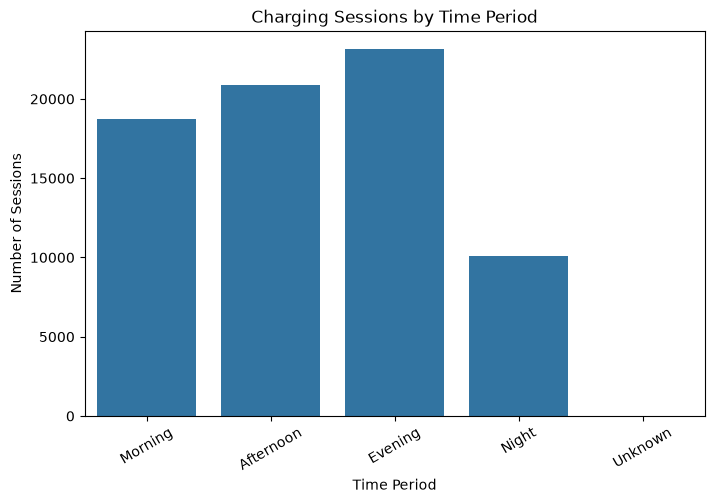

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=final_data,
    x="TimePeriod",
    order=["Morning", "Afternoon", "Evening", "Night", "Unknown"]
)

plt.title("Charging Sessions by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)
plt.show()

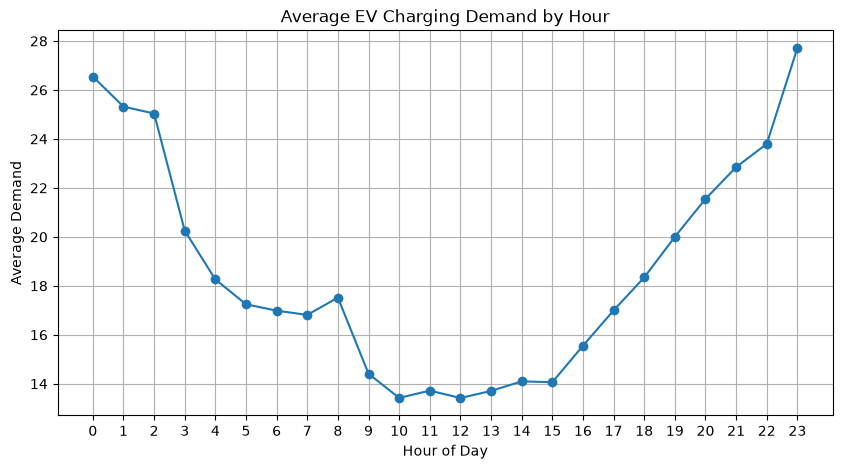

In [18]:
hourly_demand = final_data.groupby("StartHour")["Demand"].mean()

plt.figure(figsize=(10, 5))

hourly_demand.plot(kind="line", marker="o")

plt.title("Average EV Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

In [19]:
final_data.to_csv(
    "../data/feature_engineered_data.csv",
    index=False
)

print("Feature engineering completed!")

Feature engineering completed!
